In [13]:
import numpy as np

alignment_raw = np.load("target/alignment_chunk_10.npy")
alignment_raw

array([[-0.28732935,  0.5260417 , -0.31256104, ...,  0.        ,
         0.        ,  0.        ],
       [-0.5169678 ,  0.21382649, -0.23722331, ...,  0.        ,
         0.        ,  0.        ],
       [-0.31003824, -0.03462728, -0.5656738 , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [-1.0907389 , -0.9615733 , -1.3292694 , ...,  0.        ,
         0.        ,  0.        ],
       [-0.6284027 ,  0.10510763, -0.6111247 , ...,  0.        ,
         0.        ,  0.        ],
       [-0.4125773 ,  1.3587824 ,  0.234375  , ...,  0.        ,
         0.        ,  0.        ]], shape=(51, 1500), dtype=float32)

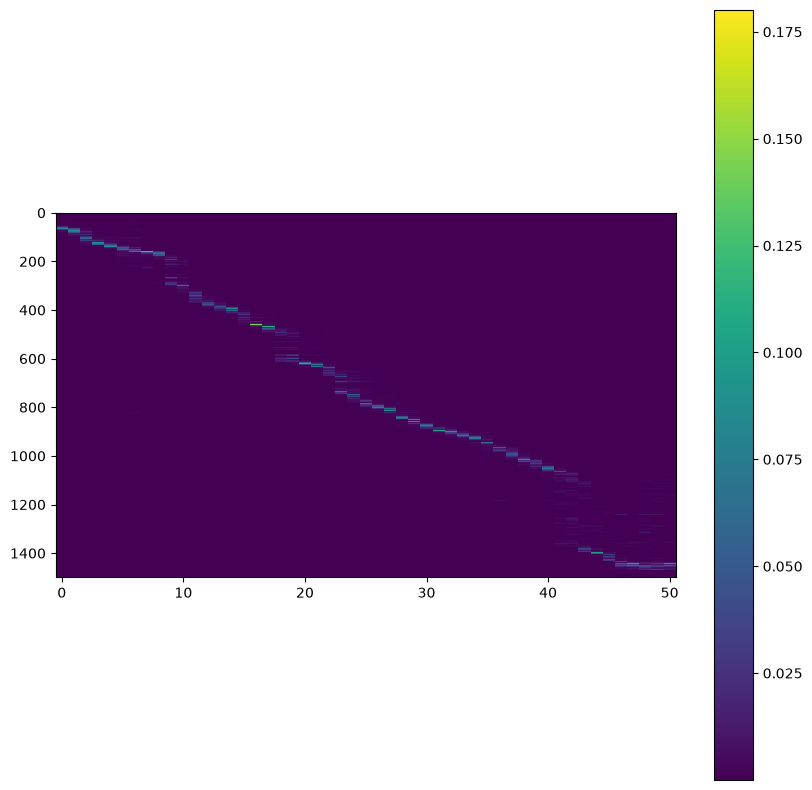

In [14]:
import matplotlib.pyplot as plt
import scipy

plt.figure(figsize=(10, 10))
alignment_row_noise_removed = alignment_raw - np.mean(alignment_raw, axis=0, keepdims=True)
alignment = scipy.special.softmax(alignment_row_noise_removed, axis=1)
plt.imshow(alignment.T, aspect=0.02, interpolation='nearest')
plt.colorbar()
plt.show()

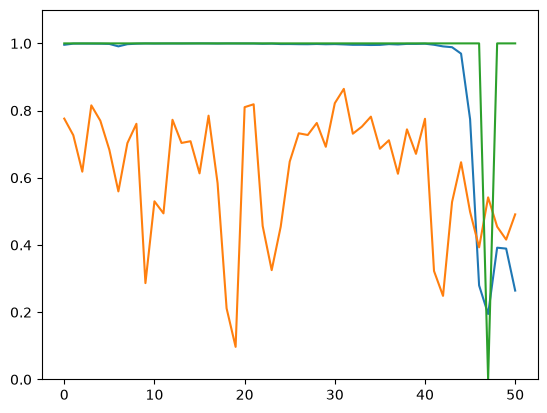

In [18]:
a = np.array(np.sum(alignment[:, :1420], axis=1))
plt.ylim(0, 1.1)
plt.plot(a)
confidence = np.sort(alignment, axis=1)[:, -100:].sum(axis=1)
confidence = np.array([alignment[i, max(0, idx-10):idx+10].sum() for i, idx in enumerate(np.argmax(alignment, axis=1))])
plt.plot(confidence)
plt.plot((a > 0.5) | (confidence < 0.5))